# First forecasting baseline: previous-week consumption

## Experiment
Predict hourly end-user energy in MWh by copying the observation **168 elapsed hours earlier**. There is no fitted model.

- Development evaluation: October 1 through December 31, 2024, using Swiss local dates.
- Forecast issue time: noon Europe/Zurich on the preceding calendar day, predicting all hours of the following local day. The autumn clock-change day has 25 target hours.
- Historical observations may be reused as they become available for subsequent daily forecasts; no target from the delivery day enters that day's forecast.
- A separate later period is still needed for final evaluation: 2024 has already been explored.

## Provisional assumptions
The source timestamps are assumed to label interval ends. We also assume that the previous-week observations used here were published by each forecast issue time. The annual workbook contains historical values and cannot establish their publication times or revision history. This is a retrospective development experiment.

A fixed 168-hour UTC lag is deliberately simple. Around daylight saving transitions it can refer to a different Swiss clock hour than the target. A baseline matching local weekday and clock hour would require an explicit policy for missing and repeated hours.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src" / "preparation.py").exists():
    project_dir = project_dir.parent
assert (project_dir / "src" / "preparation.py").exists(), "Run from the project or notebooks folder."
src_dir = str(project_dir / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from preparation import (
    load_quarter_hour_data,
    prepare_quarter_hour_data,
    aggregate_hourly_energy,
)

## 1. Reuse the preparation pipeline
This notebook runs independently of notebook 01. Loading and preparation happen here through the reusable functions.

In [2]:
file_path = project_dir / "data" / "raw" / "EnergieUebersichtCH-2024.xlsx"
raw = load_quarter_hour_data(file_path)
prepared = prepare_quarter_hour_data(raw)
hourly = aggregate_hourly_energy(prepared)

assert hourly.index.is_unique
assert hourly.index.is_monotonic_increasing
assert hourly.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert hourly["interval_count"].eq(4).all()
assert hourly["end_user_energy_mwh"].notna().all()
assert np.isclose(raw["end_user_energy_kwh"].sum(), hourly["end_user_energy_kwh"].sum(), rtol=1e-12, atol=0.01)
print(f"Prepared {len(hourly):,} complete hourly observations.")

Prepared 8,784 complete hourly observations.


## 2. Make the predictions before selecting the evaluation period
`shift(168)` moves observations forward by 168 rows. Because we checked that the UTC index is continuous and hourly, this is exactly 168 elapsed hours.

The baseline is a rolling daily experiment: a December forecast can use earlier December observations, subject to the stated availability assumption.

In [3]:
predictions = hourly[["end_user_energy_mwh", "hour_start_local"]].rename(
    columns={"end_user_energy_mwh": "actual_mwh"}
).copy()
predictions["prediction_mwh"] = predictions["actual_mwh"].shift(168)
predictions["source_start_utc"] = predictions.index - pd.Timedelta(hours=168)

# Work with local calendar dates to define noon on the preceding day.
local_dates = predictions["hour_start_local"].dt.tz_localize(None).dt.normalize()
issue_times_naive = local_dates - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
predictions["issue_time_utc"] = (
    issue_times_naive.dt.tz_localize("Europe/Zurich").dt.tz_convert("UTC")
)

start_local = pd.Timestamp("2024-10-01", tz="Europe/Zurich")
end_local = pd.Timestamp("2025-01-01", tz="Europe/Zurich")
mask = (
    (predictions["hour_start_local"] >= start_local)
    & (predictions["hour_start_local"] < end_local)
)
evaluation = predictions.loc[mask].copy()
expected_hours = int((end_local.tz_convert("UTC") - start_local.tz_convert("UTC")) / pd.Timedelta(hours=1))
assert len(evaluation) == expected_hours
assert evaluation[["actual_mwh", "prediction_mwh"]].notna().all().all()
# The complete source interval must finish before the forecast is issued.
assert (evaluation["source_start_utc"] + pd.Timedelta(hours=1) <= evaluation["issue_time_utc"]).all()

print(f"Evaluation: {len(evaluation):,} hours across {evaluation['hour_start_local'].dt.date.nunique()} local days.")
display(evaluation.head())

Evaluation: 2,209 hours across 92 local days.


,actual_mwh,hour_start_local,prediction_mwh,source_start_utc,issue_time_utc
interval_start_utc,,,,,
2024-09-30 22:00:00+00:00,5016.204679,2024-10-01 00:00:00+02:00,5083.890993,2024-09-23 22:00:00+00:00,2024-09-30 10:00:00+00:00
2024-09-30 23:00:00+00:00,4832.122369,2024-10-01 01:00:00+02:00,4914.790869,2024-09-23 23:00:00+00:00,2024-09-30 10:00:00+00:00
2024-10-01 00:00:00+00:00,4712.753045,2024-10-01 02:00:00+02:00,4776.334720,2024-09-24 00:00:00+00:00,2024-09-30 10:00:00+00:00
2024-10-01 01:00:00+00:00,4569.840501,2024-10-01 03:00:00+02:00,4631.923025,2024-09-24 01:00:00+00:00,2024-09-30 10:00:00+00:00
2024-10-01 02:00:00+00:00,4541.955075,2024-10-01 04:00:00+02:00,4576.235199,2024-09-24 02:00:00+00:00,2024-09-30 10:00:00+00:00


## 3. Measure the errors
Error is prediction minus actual energy. Positive error means overprediction.

- **MAE**: mean absolute error in MWh; the typical magnitude of error across evaluated hours.
- **RMSE**: square root of mean squared error in MWh; larger errors receive more weight.
- **Mean error**: signed average error, useful for spotting overall overprediction or underprediction. Errors can cancel here.

These metrics weight every evaluated hour equally.

In [4]:
evaluation["error_mwh"] = evaluation["prediction_mwh"] - evaluation["actual_mwh"]
evaluation["absolute_error_mwh"] = evaluation["error_mwh"].abs()

scores = pd.Series({
    "MAE (MWh)": evaluation["absolute_error_mwh"].mean(),
    "RMSE (MWh)": np.sqrt(evaluation["error_mwh"].pow(2).mean()),
    "Mean error (MWh)": evaluation["error_mwh"].mean(),
}, name="Previous-week baseline")
display(scores.round(2))

monthly_errors = (
    evaluation.assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .agg(hours=("actual_mwh", "size"), mae_mwh=("absolute_error_mwh", "mean"))
)
display(monthly_errors.round(2))

MAE (MWh)           332.26
RMSE (MWh)          445.51
Mean error (MWh)    -69.27
Name: Previous-week baseline, dtype: float64

,hours,mae_mwh
local_month,,
10,745,181.89
11,720,406.01
12,744,411.47


## 4. Inspect one week
The plot shows October 7?13 in Swiss local time. An aggregate score alone cannot show when the baseline misses peaks or changes in consumption.

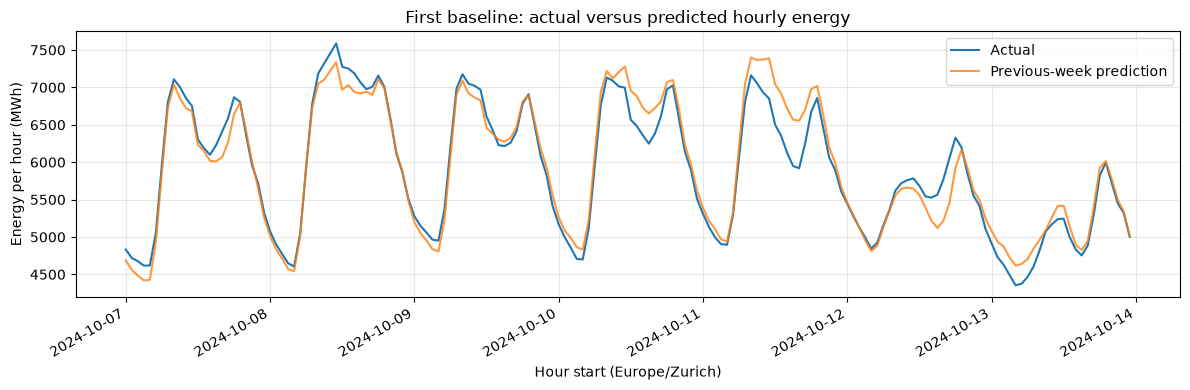

In [5]:
week = evaluation.loc[
    (evaluation["hour_start_local"] >= pd.Timestamp("2024-10-07", tz="Europe/Zurich"))
    & (evaluation["hour_start_local"] < pd.Timestamp("2024-10-14", tz="Europe/Zurich"))
]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week["hour_start_local"], week["actual_mwh"], label="Actual")
ax.plot(week["hour_start_local"], week["prediction_mwh"], label="Previous-week prediction", alpha=0.8)
ax.set_title("First baseline: actual versus predicted hourly energy")
ax.set_xlabel("Hour start (Europe/Zurich)")
ax.set_ylabel("Energy per hour (MWh)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [6]:
largest_errors = evaluation.nlargest(10, "absolute_error_mwh")

display(
    largest_errors[[
        "hour_start_local",
        "actual_mwh",
        "prediction_mwh",
        "error_mwh",
        "absolute_error_mwh",
    ]].round({
        "actual_mwh": 2,
        "prediction_mwh": 2,
        "error_mwh": 2,
        "absolute_error_mwh": 2,
    })
)

,hour_start_local,actual_mwh,prediction_mwh,error_mwh,absolute_error_mwh
interval_start_utc,,,,,
2024-12-25 07:00:00+00:00,2024-12-25 08:00:00+01:00,6278.29,8647.54,2369.25,2369.25
2024-12-25 06:00:00+00:00,2024-12-25 07:00:00+01:00,6033.71,8217.86,2184.15,2184.15
2024-12-25 10:00:00+00:00,2024-12-25 11:00:00+01:00,6242.68,8255.25,2012.57,2012.57
2024-12-25 08:00:00+00:00,2024-12-25 09:00:00+01:00,6498.94,8501.69,2002.75,2002.75
2024-12-25 09:00:00+00:00,2024-12-25 10:00:00+01:00,6491.26,8372.16,1880.89,1880.89
2024-11-22 12:00:00+00:00,2024-11-22 13:00:00+01:00,9061.45,7189.62,-1871.83,1871.83
2024-11-22 13:00:00+00:00,2024-11-22 14:00:00+01:00,8956.30,7113.30,-1843.00,1843.00
2024-12-25 13:00:00+00:00,2024-12-25 14:00:00+01:00,5979.05,7727.18,1748.14,1748.14
2024-11-22 11:00:00+00:00,2024-11-22 12:00:00+01:00,9088.02,7345.13,-1742.89,1742.89


In [7]:
daily_errors = (
    evaluation.assign(
        local_date=evaluation["hour_start_local"].dt.date
    )
    .groupby("local_date")["absolute_error_mwh"]
    .mean()
    .sort_values(ascending=False)
)

display(daily_errors.head(10).round(2).rename("daily_mae_mwh"))

local_date
2024-12-25    1101.84
2024-11-22     840.61
2024-12-24     778.75
2024-12-26     750.49
2024-12-19     748.63
2024-11-23     742.20
2024-11-21     714.06
2024-11-13     690.35
2024-12-20     658.09
2024-11-08     634.70
Name: daily_mae_mwh, dtype: float64

In [8]:
target = hourly["end_user_energy_mwh"]

# Both observations are from before the forecast issue time.
two_week_prediction = (target.shift(168) + target.shift(336)) / 2

comparison = evaluation[["actual_mwh", "prediction_mwh"]].copy()
comparison["two_week_average_mwh"] = two_week_prediction.reindex(comparison.index)

assert comparison.notna().all().all()

errors = comparison[["prediction_mwh", "two_week_average_mwh"]].sub(
    comparison["actual_mwh"], axis=0
)

display(pd.DataFrame({
    "MAE (MWh)": errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(errors.pow(2).mean()),
    "Mean error (MWh)": errors.mean(),
}).round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh)
prediction_mwh,332.26,445.51,-69.27
two_week_average_mwh,377.06,503.49,-121.51


In [9]:
monthly_mae = (
    errors.abs()
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .mean()
)

display(monthly_mae.round(2))

,prediction_mwh,two_week_average_mwh
local_month,,
10,181.89,196.99
11,406.01,489.22
12,411.47,448.82


In [10]:
monthly_bias = (
    errors
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .mean()
)

display(monthly_bias.round(2))

,prediction_mwh,two_week_average_mwh
local_month,,
10,-47.50,-79.45
11,-266.00,-425.67
12,99.31,130.73


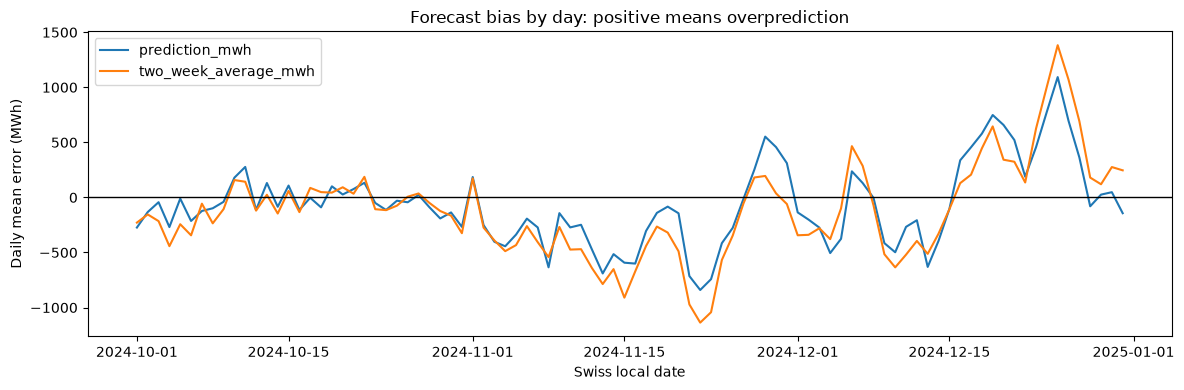

In [11]:
daily_bias = (
    errors
    .assign(local_date=evaluation["hour_start_local"].dt.date)
    .groupby("local_date")
    .mean()
)

ax = daily_bias.plot(figsize=(12, 4))
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Daily mean error (MWh)")
ax.set_xlabel("Swiss local date")
ax.set_title("Forecast bias by day: positive means overprediction")
plt.tight_layout()
plt.show()

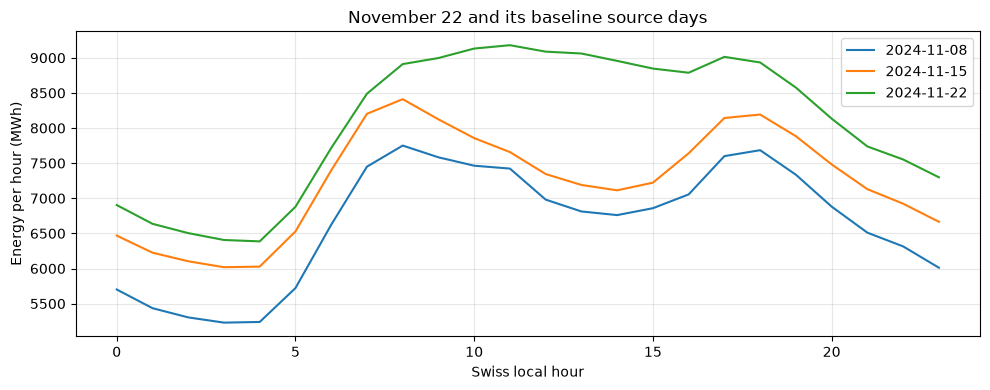

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))

for date in ["2024-11-08", "2024-11-15", "2024-11-22"]:
    day = hourly.loc[hourly["hour_start_local"].dt.strftime("%Y-%m-%d") == date]
    ax.plot(
        day["hour_start_local"].dt.hour,
        day["end_user_energy_mwh"],
        label=date,
    )

ax.set(
    xlabel="Swiss local hour",
    ylabel="Energy per hour (MWh)",
    title="November 22 and its baseline source days",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The previous-week baseline remains the better benchmark for October–December 2024: MAE 332.26 MWh versus 377.06 MWh for the two-week average. Averaging worsened MAE in every month. On November 22, consumption exceeded both source Fridays throughout the day and lacked their midday dip, revealing differences in both level and daily shape.

In [13]:
target = hourly["end_user_energy_mwh"]

# Positive means recent actual consumption exceeded last week's forecast.
recent_difference = target - target.shift(168)

# At timestamp t, use the 24 hourly intervals ending at or before t.
correction_at_issue = recent_difference.rolling(
    window=24, min_periods=24
).mean().shift(1)

adjusted = evaluation[
    ["actual_mwh", "prediction_mwh", "issue_time_utc"]
].copy()

# Freeze one correction at each day's forecast issue time.
adjusted["correction_mwh"] = adjusted["issue_time_utc"].map(
    correction_at_issue
)
adjusted["adjusted_prediction_mwh"] = (
    adjusted["prediction_mwh"] + adjusted["correction_mwh"]
)

assert adjusted.notna().all().all()

adjusted_errors = adjusted[
    ["prediction_mwh", "adjusted_prediction_mwh"]
].sub(adjusted["actual_mwh"], axis=0)

display(pd.DataFrame({
    "MAE (MWh)": adjusted_errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(adjusted_errors.pow(2).mean()),
    "Mean error (MWh)": adjusted_errors.mean(),
}).round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh)
prediction_mwh,332.26,445.51,-69.27
adjusted_prediction_mwh,287.62,384.67,-1.98


In [14]:
display(
    adjusted_errors.abs()
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .mean()
    .round(2)
)

,prediction_mwh,adjusted_prediction_mwh
local_month,,
10,181.89,192.71
11,406.01,290.41
12,411.47,379.96


In [15]:
nov22 = evaluation["hour_start_local"].dt.strftime("%Y-%m-%d").eq("2024-11-22")

display(pd.DataFrame({
    "MAE (MWh)": adjusted_errors.loc[nov22].abs().mean(),
    "Mean error (MWh)": adjusted_errors.loc[nov22].mean(),
}).round(2))

print(
    "November 22 correction:",
    round(adjusted.loc[nov22, "correction_mwh"].iloc[0], 2),
    "MWh",
)

,MAE (MWh),Mean error (MWh)
prediction_mwh,840.61,-840.61
adjusted_prediction_mwh,481.23,-465.85


November 22 correction: 374.76 MWh


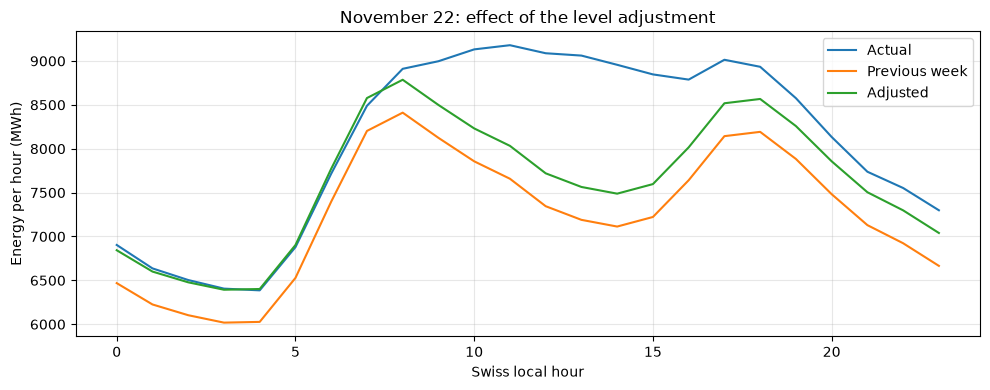

In [16]:
day = adjusted.loc[nov22]
local_hours = evaluation.loc[nov22, "hour_start_local"].dt.hour

fig, ax = plt.subplots(figsize=(10, 4))
for column, label in [
    ("actual_mwh", "Actual"),
    ("prediction_mwh", "Previous week"),
    ("adjusted_prediction_mwh", "Adjusted"),
]:
    ax.plot(local_hours, day[column], label=label)

ax.set(
    xlabel="Swiss local hour",
    ylabel="Energy per hour (MWh)",
    title="November 22: effect of the level adjustment",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
christmas = (
    evaluation["hour_start_local"]
    .dt.strftime("%Y-%m-%d")
    .eq("2024-12-25")
)

display(pd.DataFrame({
    "MAE (MWh)": adjusted_errors.loc[christmas].abs().mean(),
    "Mean error (MWh)": adjusted_errors.loc[christmas].mean(),
}).round(2))

print(
    "December 25 correction:",
    round(adjusted.loc[christmas, "correction_mwh"].iloc[0], 2),
    "MWh",
)

,MAE (MWh),Mean error (MWh)
prediction_mwh,1101.84,1092.98
adjusted_prediction_mwh,818.74,530.66


December 25 correction: -562.32 MWh


A recent-level adjustment reduced October–December MAE from 332.26 to 287.62 MWh (13.4%) and RMSE from 445.51 to 384.67 MWh. It improved November and December but slightly worsened October. It helped on both November 22 and December 25, while leaving substantial hourly errors. Results remain provisional: the adjustment assumes completed observations are immediately available, and a separate later evaluation period is still needed.

In [18]:
target = hourly["end_user_energy_mwh"]
recent_difference = target - target.shift(168)
rolling_correction = recent_difference.rolling(24, min_periods=24).mean()

def score_errors(error):
    return {
        "MAE (MWh)": error.abs().mean(),
        "RMSE (MWh)": np.sqrt(error.pow(2).mean()),
        "Mean error (MWh)": error.mean(),
    }

baseline_error = evaluation["prediction_mwh"] - evaluation["actual_mwh"]
delay_results = {
    "Previous week": score_errors(baseline_error)
}

for delay_hours in [0, 1, 6, 12, 24, 48]:
    # One hour excludes the unfinished interval; delay adds publication time.
    available_correction = rolling_correction.shift(1 + delay_hours)

    correction = evaluation["issue_time_utc"].map(available_correction)
    assert correction.notna().all(), f"Missing inputs at {delay_hours}h delay"

    prediction = evaluation["prediction_mwh"] + correction
    error = prediction - evaluation["actual_mwh"]

    delay_results[f"Adjusted: {delay_hours}h delay"] = score_errors(error)

delay_scores = pd.DataFrame.from_dict(delay_results, orient="index")
delay_scores["MAE improvement (%)"] = (
    100 * (1 - delay_scores["MAE (MWh)"] / baseline_error.abs().mean())
)

display(delay_scores.round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh),MAE improvement (%)
Previous week,332.26,445.51,-69.27,0.00
Adjusted: 0h delay,287.62,384.67,-1.98,13.44
Adjusted: 1h delay,293.85,391.44,-1.79,11.56
Adjusted: 6h delay,308.18,408.34,-0.65,7.25
Adjusted: 12h delay,316.20,416.08,0.38,4.83
Adjusted: 24h delay,338.34,447.84,5.43,-1.83
Adjusted: 48h delay,380.71,495.16,7.64,-14.58


In simulated publication-delay scenarios, the recent-level adjustment outperformed the previous-week baseline at tested delays through 12 hours, but underperformed at 24 and 48 hours. Its usefulness therefore depends on timely observations. These scenarios do not establish actual Swissgrid publication delays or account for historical revisions.

Swissgrid’s published documentation specifies initial release on the 15th working day after month-end, monthly corrections, and reliability after six months. Consequently, the recent observations used by these baselines cannot be assumed available at forecast issue time through this workbook. Reported scores describe retrospective experiments with historical values, rather than verified operational performance.
Source: https://www.swissgrid.ch/en/home/customers/topics/energy-data-ch.html

In [19]:
target = hourly["end_user_energy_mwh"]
lag = pd.Timedelta(weeks=32)

mature = evaluation[
    ["actual_mwh", "prediction_mwh", "issue_time_utc"]
].copy()

mature["mature_prediction_mwh"] = target.shift(32 * 168).reindex(mature.index)

# Check maturity using the END of each source interval.
source_end_local = (
    mature.index - lag + pd.Timedelta(hours=1)
).tz_convert("Europe/Zurich").tz_localize(None)

# Conservative policy: next month starts, then wait six calendar months.
maturity_dates = (
    source_end_local.to_period("M").to_timestamp()
    + pd.offsets.MonthBegin(1)
    + pd.DateOffset(months=6)
)
mature["assumed_available_utc"] = (
    maturity_dates.tz_localize("Europe/Zurich").tz_convert("UTC")
)

assert mature.notna().all().all()
assert (
    mature["assumed_available_utc"] <= mature["issue_time_utc"]
).all()

mature_errors = mature[
    ["prediction_mwh", "mature_prediction_mwh"]
].sub(mature["actual_mwh"], axis=0)

display(pd.DataFrame({
    "MAE (MWh)": mature_errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(mature_errors.pow(2).mean()),
    "Mean error (MWh)": mature_errors.mean(),
}).rename(index={
    "prediction_mwh": "Previous week (hindsight benchmark)",
    "mature_prediction_mwh": "32 weeks (maturity policy)",
}).round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh)
Previous week (hindsight benchmark),332.26,445.51,-69.27
32 weeks (maturity policy),1088.08,1321.50,-625.79


In [20]:
display(
    mature_errors.abs()
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .mean()
    .round(2)
)

,prediction_mwh,mature_prediction_mwh
local_month,,
10,181.89,657.77
11,406.01,1055.19
12,411.47,1550.78


In [21]:
raw_2023 = load_quarter_hour_data(
    project_dir / "data" / "raw" / "EnergieUebersichtCH-2023.xlsx"
)
hourly_2023 = aggregate_hourly_energy(
    prepare_quarter_hour_data(raw_2023)
)

assert len(hourly_2023) == 8760
assert hourly_2023["interval_count"].eq(4).all()
assert hourly_2023["end_user_energy_mwh"].notna().all()

# Include both years: some late-December targets copy early January 2024.
combined_hourly = pd.concat([hourly_2023, hourly])

assert combined_hourly.index.is_unique
assert combined_hourly.index.is_monotonic_increasing
assert combined_hourly.index.to_series().diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

annual_comparison = evaluation[["actual_mwh", "prediction_mwh"]].copy()
annual_comparison["52_week_prediction_mwh"] = (
    combined_hourly["end_user_energy_mwh"]
    .shift(52 * 168)
    .reindex(evaluation.index)
)
assert annual_comparison.notna().all().all()

annual_errors = annual_comparison[
    ["prediction_mwh", "52_week_prediction_mwh"]
].sub(annual_comparison["actual_mwh"], axis=0)

display(pd.DataFrame({
    "MAE (MWh)": annual_errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(annual_errors.pow(2).mean()),
    "Mean error (MWh)": annual_errors.mean(),
}).round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh)
prediction_mwh,332.26,445.51,-69.27
52_week_prediction_mwh,407.67,527.38,-98.45


In [22]:
monthly_comparison = pd.DataFrame({
    "Previous week (hindsight)": annual_errors["prediction_mwh"].abs(),
    "32 weeks": mature_errors["mature_prediction_mwh"].abs(),
    "52 weeks": annual_errors["52_week_prediction_mwh"].abs(),
})

display(
    monthly_comparison
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .mean()
    .round(2)
)

,Previous week (hindsight),32 weeks,52 weeks
local_month,,,
10,181.89,657.77,288.30
11,406.01,1055.19,386.91
12,411.47,1550.78,547.31


The 52-week baseline achieved an overall MAE of 407.67 MWh, improving on the 32-week baseline in every evaluated month. It satisfies our assumed maturity policy, although historical release versions remain unverified. It slightly outperformed the previous-week hindsight benchmark in November but performed worse in October and December.

In [23]:
annual_daily_mae = (
    annual_errors["52_week_prediction_mwh"].abs()
    .groupby(evaluation["hour_start_local"].dt.date)
    .mean()
    .sort_values(ascending=False)
)

display(annual_daily_mae.head(10).round(2).rename("daily_mae_mwh"))

hour_start_local
2024-12-23    1626.62
2024-12-30    1254.62
2024-12-24     918.04
2024-12-27     906.14
2024-12-28     885.56
2024-12-02     884.31
2024-11-22     844.38
2024-11-01     795.26
2024-12-10     757.41
2024-12-22     749.88
Name: daily_mae_mwh, dtype: float64

,52_week_prediction_mwh
mean,-1626.62
min,-2553.98
max,-762.10


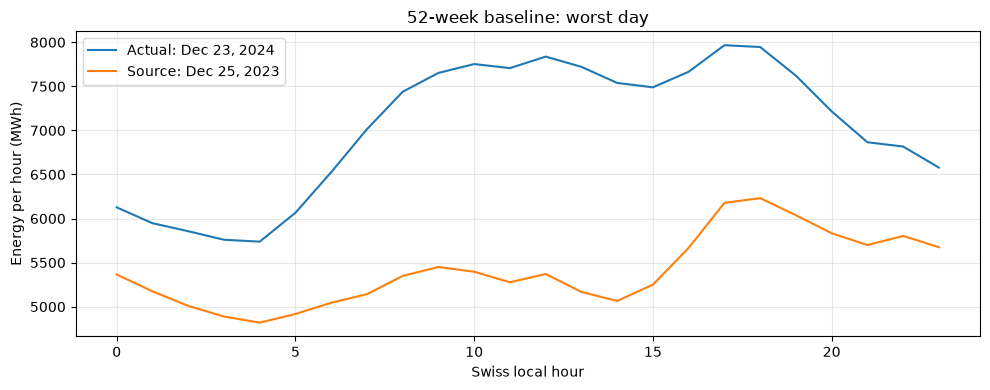

In [24]:
mask = evaluation["hour_start_local"].dt.strftime("%Y-%m-%d").eq(
    "2024-12-23"
)
day = annual_comparison.loc[mask]
local_hours = evaluation.loc[mask, "hour_start_local"].dt.hour

display(annual_errors.loc[mask, ["52_week_prediction_mwh"]].agg(
    ["mean", "min", "max"]
).round(2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(local_hours, day["actual_mwh"], label="Actual: Dec 23, 2024")
ax.plot(
    local_hours,
    day["52_week_prediction_mwh"],
    label="Source: Dec 25, 2023",
)
ax.set(
    xlabel="Swiss local hour",
    ylabel="Energy per hour (MWh)",
    title="52-week baseline: worst day",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
worst_dates = annual_daily_mae.head(10).index

source_calendar = pd.DataFrame({
    "target_local": evaluation["hour_start_local"],
    "source_local": (
        evaluation.index - pd.Timedelta(weeks=52)
    ).tz_convert("Europe/Zurich"),
})

date_pairs = (
    source_calendar
    .assign(target_date=source_calendar["target_local"].dt.date)
    .groupby("target_date")
    .agg(source_date=("source_local", lambda s: s.iloc[0].date()))
)

display(
    annual_daily_mae.head(10).rename("daily_mae_mwh")
    .to_frame()
    .join(date_pairs)
    .round(2)
)

,daily_mae_mwh,source_date
hour_start_local,,
2024-12-23,1626.62,2023-12-25
2024-12-30,1254.62,2024-01-01
2024-12-24,918.04,2023-12-26
2024-12-27,906.14,2023-12-29
2024-12-28,885.56,2023-12-30
2024-12-02,884.31,2023-12-04
2024-11-22,844.38,2023-11-24
2024-11-01,795.26,2023-11-03
2024-12-10,757.41,2023-12-12


In [26]:
local_dates = evaluation["hour_start_local"]
december = local_dates.dt.month.eq(12)
late_december = december & local_dates.dt.day.between(22, 30)

abs_error = annual_errors["52_week_prediction_mwh"].abs()

display(pd.DataFrame({
    "Hours": [
        late_december.sum(),
        (december & ~late_december).sum(),
    ],
    "MAE (MWh)": [
        abs_error.loc[late_december].mean(),
        abs_error.loc[december & ~late_december].mean(),
    ],
    "Share of December absolute error (%)": [
        100 * abs_error.loc[late_december].sum() / abs_error.loc[december].sum(),
        100 * abs_error.loc[december & ~late_december].sum()
        / abs_error.loc[december].sum(),
    ],
}, index=["December 22–30", "Other December days"]).round(2))

,Hours,MAE (MWh),Share of December absolute error (%)
December 22–30,216,822.95,43.65
Other December days,528,434.54,56.35


In [27]:
# Group by local date and clock hour, averaging repeated source hours.
local_history = combined_hourly["end_user_energy_mwh"].copy()
local_history.index = (
    combined_hourly["hour_start_local"].dt.tz_localize(None)
)
local_history = local_history.groupby(level=0).mean()

target_local = pd.DatetimeIndex(
    evaluation["hour_start_local"].dt.tz_localize(None)
)
source_local = target_local - pd.DateOffset(years=1)

calendar_prediction = pd.Series(
    local_history.reindex(source_local).to_numpy(),
    index=evaluation.index,
)

# Missing source clock hours use the existing 52-week prediction.
fallback = calendar_prediction.isna()
calendar_prediction = calendar_prediction.fillna(
    annual_comparison["52_week_prediction_mwh"]
)

# Apply our existing conservative maturity policy.
source_maturity = (
    source_local.to_period("M").to_timestamp()
    + pd.offsets.MonthBegin(1)
    + pd.DateOffset(months=6)
).tz_localize("Europe/Zurich").tz_convert("UTC")

assert (source_maturity <= evaluation["issue_time_utc"]).all()
assert calendar_prediction.notna().all()

calendar_comparison = annual_comparison.copy()
calendar_comparison["calendar_year_prediction_mwh"] = calendar_prediction

calendar_errors = calendar_comparison[[
    "prediction_mwh",
    "52_week_prediction_mwh",
    "calendar_year_prediction_mwh",
]].sub(calendar_comparison["actual_mwh"], axis=0)

print(f"Hours using the 52-week fallback: {fallback.sum()}")

display(pd.DataFrame({
    "MAE (MWh)": calendar_errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(calendar_errors.pow(2).mean()),
    "Mean error (MWh)": calendar_errors.mean(),
}).round(2))

Hours using the 52-week fallback: 0


,MAE (MWh),RMSE (MWh),Mean error (MWh)
prediction_mwh,332.26,445.51,-69.27
52_week_prediction_mwh,407.67,527.38,-98.45
calendar_year_prediction_mwh,745.64,966.31,-116.70


In [28]:
display(
    calendar_errors[[
        "52_week_prediction_mwh",
        "calendar_year_prediction_mwh",
    ]]
    .abs()
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month")
    .mean()
    .round(2)
)

,52_week_prediction_mwh,calendar_year_prediction_mwh
local_month,,
10,288.30,709.25
11,386.91,757.49
12,547.31,770.60


Matching the previous year’s local calendar date and hour produced MAE of 745.64 MWh, versus 407.67 MWh for the 52-week baseline. It performed worse in October, November, and December. No missing-hour fallback was needed. The 52-week baseline remains our preferred baseline under the assumed maturity policy; historical release versions remain unverified.
